<a href="https://colab.research.google.com/github/RamiroFernandez22/tp-finanzas-computacionales/blob/main/TP_Integrador_FINAL_reestructurado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP Finanzas Computacionales — Motor + Calibración (Fases 1 a 6)

Cuaderno **listo para correr con las 500 acciones reales**.
Para usarlo: **Ejecutar todo**.

Los datos( 6 archivos csv) se descargan automaticamente del repositorio de GitHub del TP en el paso 0.

**Qué hace este cuaderno, en orden (la historia del trabajo):**
1. Pasos 0–3: **la idea y su factibilidad.** Carga los datos y el motor, y corre una
   primera versión de la estrategia (disparada por la Fed, con valores de partida
   N=5, M=5 y ventana de 1 año) comparada con el SPY, el benchmark sintético y 1/N.
2. Pasos 4–6: **la calibración.** Con backtesting hacia adelante se decide cuántos datos
   usa Markowitz (1, 2 o 3 años), cada cuánto rebalancear (Fed contra 1, 2, 3, 4 y 6
   meses) y cuántos sectores y acciones por sector (grilla N×M).
3. Paso 7: **la cartera final**, armada con los criterios elegidos, con su validación año
   a año, su comportamiento por régimen de tasa y la comparación contra el punto de partida.
4. Pasos 8–11: **análisis de la cartera final** (VaR por tres métodos, CAPM, stress
   testing, gráficos de capital, caídas, volatilidad móvil y frontera eficiente), la
   reacción sectorial a la Fed y los chequeos. Todo se calcula solo sobre la cartera final.

> La calibración (Pasos 4–6) **decide los números con los datos**: para cada opción se
> mira cómo rinde en el período que NO usó para elegir (fuera de muestra).


## Paso 0 — Conectar GitHub

In [41]:

# PASO 0 — Descargar los datos desde GitHub
# Se clona el repositorio del TP, que trae la carpeta "Datos" con los 6 CSV.
import os, subprocess

REPO = "https://github.com/RamiroFernandez22/tp-finanzas-computacionales.git"
DESTINO = "tp-finanzas-computacionales"

if not os.path.exists(DESTINO):
    subprocess.run(["git", "clone", "--depth", "1", REPO, DESTINO], check=True)

CARPETA = f"{DESTINO}/Datos"
print("Carpeta de datos:", CARPETA)


Carpeta de datos: tp-finanzas-computacionales/Datos


## Paso 1 — El motor

Todo el código de la estrategia, en clases y comentado. Corré la celda y seguí.

In [42]:
"""
TP INTEGRADOR — FINANZAS COMPUTACIONALES (UADE, 2do cuatrimestre 2026)
Estrategia: rotación sectorial por momentum con rebalanceo en cada reunión de la Fed.

Contiene:
  - Config            : rutas y parámetros en un solo lugar.
  - DataLoader        : lee los CSV, valida, alinea calendarios y arma retornos.
  - SenalesUniverso   : MM50, distancia, elegibilidad, breadth y selección N/M.
  - Optimizador       : Markowitz (máx. Sharpe / mínima varianza) y frontera eficiente.
  - CarteraDosNiveles : Markowitz anidado (acciones dentro del sector, luego sectores).
  - curva_valor / maximum_drawdown / volatilidad_rolling : métricas de series.
  - Backtester        : motor de rebalanceo; parametrizable por N, M, ventana y fechas.
  - RiskMetrics       : VaR paramétrico, histórico y Monte Carlo.
  - CAPM              : Alpha y Beta por Cov/Var (como en la Clase 11).
  - RateSensitivity   : betas sector-tasa (alternativa evaluada; no entra en el resultado final).
  - StressTester      : escenarios históricos y shocks hipotéticos.
  - Calibrador        : compara ventana de datos, frecuencia de rebalanceo y grilla N×M
                        (calibración/validación, estabilidad año a año y regímenes de tasa).
  - ReaccionFOMC      : reacción de cada sector el día de la reunión de la Fed.

Todo el código está en POO y usa operaciones vectorizadas de NumPy/Pandas; el único
loop principal es sobre las fechas de rebalanceo. El motor no descarga nada: lee los
CSV de la carpeta de datos (el Paso 0 los trae de GitHub).
"""

import os
import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import minimize, LinearConstraint, Bounds


# CONFIG: un único lugar para rutas y parámetros
class Config:
    """
    Reúne en un solo lugar las rutas a los CSV y los parámetros de la estrategia,
    para no tener "números mágicos" sueltos por el código.
    """

    def __init__(self, carpeta_datos="tp-finanzas-computacionales/Datos"):
        self.carpeta_datos = carpeta_datos

        # Nombres de los archivos CSV
        self.archivo_precios_acciones = "precios_acciones_sp500.csv"
        self.archivo_precios_mercado = "precios_spy_y_etfs_sectoriales.csv"
        self.archivo_tickers = "sp500_tickers_sectores.csv"
        self.archivo_dtb3 = "tasa_libre_riesgo_dtb3.csv"
        self.archivo_dff = "tasa_fondos_federales_dff.csv"
        self.archivo_fomc = "fechas_fomc-v2.csv"

        # Parámetros de la estrategia
        self.mm_ventana = 50
        self.min_historia = 252
        self.ventana_cov = 252
        self.min_rupturas_sector = 3

        # Valores por defecto (corrida de referencia). La configuración final
        # (N=3, M=6) sale de la calibración de los Pasos 4 a 7.
        self.N_sectores = 5
        self.M_acciones = 5

        # Convenciones
        self.dias_anio = 252

        # Restricciones de Markowitz
        self.tope_activo = 0.40
        self.tope_sector = 0.40
        self.objetivo = "sharpe"

        # Riesgo (VaR a 1 día)
        self.niveles_confianza_var = (0.95, 0.99)
        self.n_simulaciones_mc = 10000
        self.semilla = 42

        # Métricas
        self.ventana_vol_rolling = 63  # ruedas ( aproximadamente 3 meses) para la volatilidad móvil

        # Sector GICS -> ETF SPDR, para armar el benchmark sintético.
        self.mapa_sector_etf = {
            "Information Technology": "XLK",
            "Financials": "XLF",
            "Energy": "XLE",
            "Health Care": "XLV",
            "Industrials": "XLI",
            "Consumer Discretionary": "XLY",
            "Consumer Staples": "XLP",
            "Utilities": "XLU",
            "Materials": "XLB",
            "Real Estate": "XLRE",
            "Communication Services": "XLC",
        }

    def ruta(self, nombre_archivo):
        """Arma la ruta completa a un archivo de datos."""
        return os.path.join(self.carpeta_datos, nombre_archivo)



# DATALOADER — lee, valida y prepara todos los datos
class DataLoader:
    """
    Responsable de dejar los datos listos para trabajar:
      1. Lee los CSV de precios, tasas, tickers/sectores y fechas de la Fed.
      2. Valida (fechas ordenadas, sin duplicados, tasas sin huecos).
      3. Alinea las series de distinta frecuencia al calendario diario de precios,
         usando forward-fill para las tasas (días sin dato toman el último valor).
      4. Calcula los retornos simples diarios.
      5. Arma la lista de fechas de rebalanceo (reuniones FOMC con historia suficiente).

    No modifica los archivos originales: solo los lee.
    """

    def __init__(self, config: Config, usar_acciones=True):
        self.cfg = config
        # usar_acciones=False: modo de prueba con los ETFs, sin el archivo de las 503 acciones.
        self.usar_acciones = usar_acciones

        # Atributos que se llenan en cargar():
        self.precios = None            # DataFrame ruedas x tickers (universo de acciones)
        self.retornos = None           # retornos simples diarios del universo
        self.precios_mercado = None    # DataFrame ruedas x [SPY, XLK, ...]
        self.sectores = None           # Serie ticker -> sector
        self.dtb3 = None               # tasa libre de riesgo, en TANTO POR UNO, alineada y rellenada
        self.rf_diaria = None          # tasa libre de riesgo diaria (DTB3/252). DTB3: Daily Treasury Bills de 3 meses
        self.dff = None                # tasa de fondos federales, en tanto por uno, alineada. DFF: Tasa de fondos federales
        self.fechas_fomc = None        # todas las reuniones (DatetimeIndex)
        self.fechas_rebalanceo = None  # reuniones utilizables, mapeadas a ruedas de mercado
        self.calendario = None         # índice de fechas base (el de los precios)

    #  utilidades internas de lectura
    def _leer_precios(self, ruta):
        """
        Lee un CSV de precios con formato 'Date' + una columna por activo.
        Deja la fecha como índice (tipo datetime) y los precios como números.
        """
        df = pd.read_csv(ruta)
        col_fecha = df.columns[0]
        df[col_fecha] = pd.to_datetime(df[col_fecha])
        df = df.set_index(col_fecha).sort_index()
        df = df.apply(pd.to_numeric, errors="coerce")
        return df

    def _leer_tasa(self, ruta, nombre_col):
        """
        Lee un CSV de tasa (columnas 'fecha' y la tasa en % anual) y devuelve una
        Serie indexada por fecha, convertida a decimales(dividida por 100).
        """
        df = pd.read_csv(ruta)
        df.columns = ["fecha", nombre_col]
        df["fecha"] = pd.to_datetime(df["fecha"])
        serie = df.set_index("fecha")[nombre_col].sort_index()
        serie = pd.to_numeric(serie, errors="coerce") / 100.0
        return serie

    def _alinear_tasa(self, serie):
        """
        Lleva una tasa al calendario diario de precios y rellena hacia adelante:
        cada rueda sin dato (feriado, fin de semana) toma el último valor conocido.
        Es lo correcto para una tasa: se mantiene vigente hasta que cambia.
        """
        return serie.reindex(self.calendario).ffill()

    # carga principal
    def cargar(self):
        """Ejecuta toda la preparación de datos y devuelve self (encadenable)."""
        cfg = self.cfg

        # 1) Precios del universo (acciones). En modo prueba usamos los ETFs
        ruta_univ = cfg.ruta(cfg.archivo_precios_acciones if self.usar_acciones
                             else cfg.archivo_precios_mercado)
        self.precios = self._leer_precios(ruta_univ)
        self.calendario = self.precios.index   # calendario base = ruedas de precios

        # 2) Retornos simples diarios: (precio_hoy / precio_ayer) - 1.
        self.retornos = self.precios.pct_change()

        # 3) Precios de mercado (SPY + 11 ETFs sectoriales).
        self.precios_mercado = self._leer_precios(cfg.ruta(cfg.archivo_precios_mercado))

        # 4) Mapa ticker -> sector.
        tmap = pd.read_csv(cfg.ruta(cfg.archivo_tickers))
        tmap.columns = ["ticker", "sector"]
        self.sectores = tmap.set_index("ticker")["sector"]

        # 5) Tasas, convertidas a tanto por uno y alineadas al calendario.
        self.dtb3 = self._alinear_tasa(self._leer_tasa(cfg.ruta(cfg.archivo_dtb3), "DTB3"))
        self.dff = self._alinear_tasa(self._leer_tasa(cfg.ruta(cfg.archivo_dff), "DFF"))
        # Tasa libre de riesgo diaria: la anual se reparte entre 252 ruedas.
        self.rf_diaria = self.dtb3 / cfg.dias_anio

        # 6) Fechas del FOMC y fechas de rebalanceo utilizables.
        self._preparar_fechas_fomc()

        return self

    def _preparar_fechas_fomc(self):
        """
        Lee las fechas del FOMC y arma la lista de rebalanceos que se pueden usar.
        Una reunión es utilizable si:
          - la mapeamos a una rueda de mercado (la propia reunión o la rueda
            siguiente si cayó en un día no bursátil),
          - antes de esa rueda hay al menos `min_historia` ruedas (para calcular
            MM50 y covarianza sin inventar datos),
          - existe una rueda siguiente (t+1) para medir el retorno de la cartera.
        """
        cfg = self.cfg
        raw = pd.read_csv(cfg.ruta(cfg.archivo_fomc))
        fechas = pd.to_datetime(raw[raw.columns[0]]).sort_values()
        self.fechas_fomc = pd.DatetimeIndex(fechas.unique())

        cal = self.calendario
        rebal = []
        for f in self.fechas_fomc:
            # Primera rueda de mercado en o después de la reunión (cierre del día t).
            pos = cal.searchsorted(f, side="left")
            if pos >= len(cal):
                continue  # la reunión es posterior al último dato de precios
            # Condiciones: historia suficiente antes de t, y que exista t+1.
            if pos >= cfg.min_historia and pos < len(cal) - 1:
                rebal.append(cal[pos])
        self.fechas_rebalanceo = pd.DatetimeIndex(pd.Index(rebal).unique())

    # validación
    def validar(self):
        """
        Devuelve una lista de chequeos (descripcion, resultado, estado OK/FALLA)
        para confirmar que los datos quedaron bien preparados.
        """
        chequeos = []

        def add(desc, ok, detalle=""):
            chequeos.append((desc, detalle, "OK" if ok else "FALLA"))

        # 1) Fechas ordenadas y sin duplicados en precios.
        idx = self.precios.index
        add("Fechas de precios ordenadas", idx.is_monotonic_increasing)
        add("Sin fechas duplicadas en precios", not idx.has_duplicates,
            f"{idx.duplicated().sum()} duplicadas")

        # 2) Retornos: la primera fila debe ser NaN (no hay día previo).
        primera_fila_nan = self.retornos.iloc[0].isna().all()
        add("Primera fila de retornos es NaN (sin día previo)", primera_fila_nan)

        # 3) Tasas alineadas al calendario y sin NaN tras el forward-fill(rellenar hacia delante).
        add("DTB3 alineada al calendario de precios",
            self.dtb3.index.equals(self.calendario))
        add("DFF sin huecos(feriados rellenados con el ultimo dato)", self.dff.isna().sum() == 0,
            f"{int(self.dff.isna().sum())} NaN")

        # 4) Rango de tasas razonable (en tanto por uno: 0 a 0.07).
        add("DTB3 en rango razonable (0%–7% anual)",
            float(self.dtb3.max()) < 0.07, f"máx={float(self.dtb3.max()):.4f}")

        # 5) Sectores: 11 sectores GICS.
        n_sec = self.sectores.nunique()
        add("11 sectores GICS", n_sec == 11, f"{n_sec} sectores")

        # 6) Fechas de rebalanceo dentro del rango y con historia suficiente.
        hay_rebal = len(self.fechas_rebalanceo) > 0
        add("Hay fechas de rebalanceo utilizables", hay_rebal,
            f"{len(self.fechas_rebalanceo)} rebalanceos")
        if hay_rebal:
            primera = self.fechas_rebalanceo[0]
            pos = self.calendario.searchsorted(primera)
            add("Primer rebalanceo tiene >=252 ruedas de historia", pos >= self.cfg.min_historia,
                f"{pos} ruedas antes del {primera.date()}")

        return chequeos



# SEÑALES — momentum por acción y selección de sectores y acciones
class SenalesUniverso:
    """
    Calcula las señales de momentum de TODO el universo de una sola vez
    (vectorizado) y después, para cada fecha de rebalanceo, arma la selección
    de sectores (etapa 1) y de acciones (etapa 2).

    Matrices (todas con la misma forma: ruedas x tickers):
      - mm        : media móvil de `mm_ventana` ruedas del precio.
      - distancia : (precio - mm) / mm  -> cuán por encima/por debajo de la media está.
      - ruptura   : True si el precio está por encima de su media (señal alcista).
      - elegible  : True si la acción ya acumuló >= `min_historia` ruedas con precio
                    y tiene precio ese día (evita usar acciones sin historia suficiente).

    Importante (sin mirar el futuro): la media móvil en la rueda t usa solo precios
    de t y anteriores; nunca datos posteriores a t.
    """

    def __init__(self, precios: pd.DataFrame, sectores: pd.Series, config: Config):
        self.cfg = config
        self.precios = precios
        self.sectores = sectores

        v = config.mm_ventana
        self.mm = precios.rolling(window=v, min_periods=v).mean()
        self.distancia = (precios - self.mm) / self.mm
        self.ruptura = (precios > self.mm) & self.mm.notna()
        observados = precios.notna().cumsum()
        self.elegible = (observados >= config.min_historia) & precios.notna()

    def _tabla_en_fecha(self, t):
        """
        Arma una tabla (una fila por ticker) con sector, elegibilidad, ruptura y
        distancia en la rueda t. Base para las etapas 1 y 2.
        """
        tickers = self.precios.columns
        tabla = pd.DataFrame({
            "sector": self.sectores.reindex(tickers).values,
            "elegible": self.elegible.loc[t].values,
            "ruptura": self.ruptura.loc[t].reindex(tickers).fillna(False).values,
            "distancia": self.distancia.loc[t].values,
        }, index=tickers)
        # Una acción "cuenta" para el momentum del sector solo si es elegible y rompió la media.
        tabla["elig_y_rup"] = tabla["elegible"] & tabla["ruptura"]
        return tabla.dropna(subset=["sector"])

    def breadth_sectorial(self, t):
        """
        Etapa 1 (sectores). Para cada sector calcula:
          - n_elegibles      : acciones elegibles del sector,
          - n_rupturas       : elegibles que además rompieron su MM50,
          - breadth          : n_rupturas / n_elegibles (proporción con momentum).
        Devuelve un DataFrame ordenado por breadth descendente.
        """
        tabla = self._tabla_en_fecha(t)
        g = tabla.groupby("sector")
        resumen = pd.DataFrame({
            "n_elegibles": g["elegible"].sum(),
            "n_rupturas": g["elig_y_rup"].sum(),
        })
        # breadth = proporción de elegibles por encima de su media (0 si no hay elegibles).
        resumen["breadth"] = np.where(
            resumen["n_elegibles"] > 0,
            resumen["n_rupturas"] / resumen["n_elegibles"].replace(0, np.nan),
            0.0,
        )
        resumen["breadth"] = resumen["breadth"].fillna(0.0)
        return resumen.sort_values("breadth", ascending=False)

    def seleccionar(self, t, N=None, M=None):
        """
        Selección completa en la rueda t:
          Etapa 1: descarta sectores con menos de `min_rupturas_sector` rupturas y
                  toma los N sectores con mayor breadth.
          Etapa 2: dentro de cada sector elegido, toma hasta M acciones que rompieron
                  la media, ordenadas por distancia (P-MM50)/MM50 descendente.
        Devuelve: (lista_sectores_elegidos, dict sector -> lista de tickers, tabla_breadth).

        N y M se pueden pasar por parámetro (los usa la calibración); si quedan en None,
        se toman de Config. Las señales no dependen de N ni de M, así que no se recalculan.
        """
        cfg = self.cfg
        N = cfg.N_sectores if N is None else N
        M = cfg.M_acciones if M is None else M
        resumen = self.breadth_sectorial(t)
        # Etapa 1: solo sectores con suficientes rupturas, y de esos los N mejores.
        candidatos = resumen[resumen["n_rupturas"] >= cfg.min_rupturas_sector]
        sectores_elegidos = list(candidatos.head(N).index)

        # Etapa 2: ranking de acciones por distancia dentro de cada sector elegido.
        tabla = self._tabla_en_fecha(t)
        seleccion = {}
        for sector in sectores_elegidos:
            cand = tabla[(tabla["sector"] == sector) & (tabla["elig_y_rup"])]
            mejores = cand.sort_values("distancia", ascending=False).head(M)
            seleccion[sector] = list(mejores.index)
        return sectores_elegidos, seleccion, resumen



# OPTIMIZADOR MARKOWITZ

class Optimizador:
    """
    Optimización de Markowitz sobre una ventana de retornos: se estima el retorno esperado y la matriz de covarianza, y se
    buscan los pesos óptimos con `scipy.optimize.minimize` (método SLSQP).

    Dos objetivos disponibles:
      - "min_var": mínima varianza  ->  minimizar  wᵀ Σ w.
      - "sharpe" : máximo Sharpe     ->  minimizar  -(wᵀμ − rf) / sqrt(wᵀ Σ w).

    Restricciones: long-only (sin ventas en corto), los pesos suman 1 y cada
    peso tiene un tope (caja). Todo anualizado con 252 ruedas.
    """

    def __init__(self, config: Config):
        self.cfg = config

    @staticmethod
    def retorno_esperado(retornos_ventana):
        """Retorno esperado anual = media diaria * 252 (una media por activo)."""
        return retornos_ventana.mean().values * 252

    @staticmethod
    def covarianza(retornos_ventana):
        """Matriz de covarianza anual = covarianza diaria * 252."""
        return retornos_ventana.cov().values * 252

    def _tope_factible(self, n, tope):
        """
        Si con n activos el tope impide sumar 1 (n*tope < 1), lo relajamos a 1
        (sin tope) para que el problema tenga solución. Caso típico: un sector
        con muy pocas acciones.
        """
        if tope is None:
            return 1.0
        return tope if n * tope >= 1.0 else 1.0

    def optimizar(self, retornos_ventana, rf_anual=0.0, tope=None, objetivo=None):
        """
        Devuelve un np.array de pesos (en el orden de las columnas de
        `retornos_ventana`). Con un solo activo, devuelve peso 1.
        """
        objetivo = objetivo or self.cfg.objetivo
        cols = list(retornos_ventana.columns)
        n = len(cols)
        if n == 1:
            return np.array([1.0])

        mu = self.retorno_esperado(retornos_ventana)
        Sigma = self.covarianza(retornos_ventana)

        def varianza_portafolio(w):
            return w @ Sigma @ w

        def neg_sharpe(w):
            ret = w @ mu
            vol = np.sqrt(w @ Sigma @ w)
            return -(ret - rf_anual) / vol if vol > 0 else 0.0

        funcion = varianza_portafolio if objetivo == "min_var" else neg_sharpe
        tope_ef = self._tope_factible(n, tope)
        limites = Bounds(lb=np.zeros(n), ub=np.full(n, tope_ef))   # long-only + tope
        suma_uno = LinearConstraint(np.ones(n), 1, 1)              # pesos suman 1
        w0 = np.full(n, 1.0 / n)                                   # arranque: 1/N

        res = minimize(funcion, w0, method="SLSQP",
                       bounds=limites, constraints=suma_uno,
                       options={"maxiter": 1000, "ftol": 1e-12})
        w = res.x
        # Corrige redondeos: los pesos apenas negativos pasan a 0
        # y se reescala para que sumen 1
        w = np.clip(w, 0, None)
        w = w / w.sum()
        return w

    @staticmethod
    def metricas(w, retornos_ventana, rf_anual=0.0):
        """Retorno, volatilidad y Sharpe anuales de una cartera de pesos w."""
        mu = retornos_ventana.mean().values * 252
        Sigma = retornos_ventana.cov().values * 252
        ret = float(w @ mu)
        vol = float(np.sqrt(w @ Sigma @ w))
        sharpe = (ret - rf_anual) / vol if vol > 0 else np.nan
        return {"retorno": ret, "vol": vol, "sharpe": sharpe}

    def frontera_eficiente(self, retornos_ventana, n_puntos=30):
        """
        Barre retornos objetivo entre el mínimo y el máximo esperado y, para cada
        uno, busca la cartera de mínima varianza con ese retorno. Sirve para graficar la frontera y para chequear que a mas riesgo mas retorno.
        """
        cols = list(retornos_ventana.columns)
        n = len(cols)
        mu = self.retorno_esperado(retornos_ventana)
        Sigma = self.covarianza(retornos_ventana)
        objetivos = np.linspace(mu.min(), mu.max(), n_puntos)
        vols, rets = [], []
        for r_obj in objetivos:
            cons = [
                {"type": "eq", "fun": lambda w: np.sum(w) - 1},
                {"type": "eq", "fun": lambda w, r=r_obj: w @ mu - r},
            ]
            res = minimize(lambda w: w @ Sigma @ w, np.full(n, 1.0 / n),
                           method="SLSQP", bounds=[(0, 1)] * n, constraints=cons,
                           options={"maxiter": 1000, "ftol": 1e-12})
            if res.success:
                vols.append(np.sqrt(res.fun)); rets.append(r_obj)
        return np.array(rets), np.array(vols)



# CARTERA DE DOS NIVELES — Markowitz en dos niveles
class CarteraDosNiveles:
    """
    Construye la cartera madre en dos niveles:

      Nivel 1 (dentro de cada sector): se optimizan los pesos de las acciones
               elegidas del sector. Con esos pesos se arma la "cartera sectorial"
               y su serie de retornos diarios en la ventana.
      Nivel 2 (entre sectores): se tratan las carteras sectoriales como si fueran
               activos y se optimizan los pesos de cada sector en la cartera madre.

      Peso final de cada acción = (peso del sector) × (peso de la acción dentro
      del sector). La suma de todos los pesos finales da 1.
    """

    def __init__(self, config: Config, optimizador: Optimizador = None):
        self.cfg = config
        self.opt = optimizador or Optimizador(config)

    def construir(self, seleccion, retornos_ventana, rf_anual=0.0):
        """
        Parámetros:
          seleccion        : dict sector -> lista de tickers (sale de SenalesUniverso).
          retornos_ventana : DataFrame de retornos diarios (ventana) con columnas
                             que incluyen a todos los tickers seleccionados.
          rf_anual         : tasa libre de riesgo anual para el objetivo Sharpe.

        Devuelve:
          pesos_finales    : Serie ticker -> peso (suma 1).
          traza            : dict con los pesos dentro de cada sector y los de cada sector.
        """
        cfg = self.cfg
        pesos_intra = {}
        ret_sectoriales = {}

        # Nivel 1: optimización dentro de cada sector
        for sector, tickers in seleccion.items():
            if len(tickers) == 0:
                continue
            r_sec = retornos_ventana[tickers].dropna(how="any")
            w = self.opt.optimizar(r_sec, rf_anual=rf_anual,
                                   tope=cfg.tope_activo, objetivo=cfg.objetivo)
            pesos_intra[sector] = pd.Series(w, index=tickers)
            # Retorno diario de la cartera sectorial = retornos ponderados
            ret_sectoriales[sector] = (retornos_ventana[tickers] * w).sum(axis=1)

        sectores = list(ret_sectoriales.keys())
        if len(sectores) == 0:
            return pd.Series(dtype=float), {"intra": {}, "sectores": {}}

        # Nivel 2: optimización entre carteras sectoriales
        ret_sec_df = pd.DataFrame(ret_sectoriales).dropna(how="any")
        w_sec = self.opt.optimizar(ret_sec_df, rf_anual=rf_anual,
                                  tope=cfg.tope_sector, objetivo=cfg.objetivo)
        pesos_sector = pd.Series(w_sec, index=sectores)

        # Combinación: peso final = peso_sector * peso_intra
        pesos_finales = {}
        for sector in sectores:
            for ticker, w_intra in pesos_intra[sector].items():
                pesos_finales[ticker] = pesos_sector[sector] * w_intra
        pesos_finales = pd.Series(pesos_finales)
        pesos_finales = pesos_finales / pesos_finales.sum()   # normaliza (por seguridad)

        traza = {"intra": pesos_intra, "sectores": pesos_sector}
        return pesos_finales, traza



# MÉTRICAS DE SERIES — capital acumulado, drawdown y volatilidad móvil
def curva_valor(retornos, valor_inicial=1.0):
    """
    Convierte una serie de retornos diarios en una curva de valor (capital
    acumulado), empezando en `valor_inicial`. Es el producto acumulado de (1+r).
    """
    return valor_inicial * (1 + retornos.fillna(0)).cumprod()


def maximum_drawdown(valor):
    """
    Máxima caída desde un pico (Maximum Drawdown). Para cada día se mide cuánto
    cayó el capital respecto del máximo alcanzado hasta ese momento; se devuelve
    la peor de esas caídas (un número <= 0).
    """
    pico = valor.cummax()
    caida = valor / pico - 1
    return float(caida.min())


def volatilidad_rolling(retornos, ventana=63):
    """
    Volatilidad móvil anualizada: desvío estándar de los retornos en una ventana
    de `ventana` ruedas, multiplicado por sqrt(252) para llevarlo a términos anuales.
    """
    return retornos.rolling(ventana).std() * np.sqrt(252)



# BACKTESTER — motor de rebalanceo
class Backtester:
    """
    Recorre las fechas de rebalanceo (por defecto, las reuniones del FOMC) y, en cada una:
      1. Pide la selección de sectores y acciones (SenalesUniverso).
      2. Optimiza la cartera en dos niveles (CarteraDosNiveles) con la ventana de datos.
      3. Mantiene esos pesos desde el día siguiente (t+1) hasta el próximo
         rebalanceo, acumulando el retorno diario de la cartera.
    Si en un rebalanceo no sobrevive ningún sector, ese tramo se invierte en caja
    a la tasa libre de riesgo.

    Un único loop sobre fechas de rebalanceo; todo lo de adentro (retornos,
    covarianzas, pesos) es vectorizado.

    Carteras que se calculan en paralelo para comparar:
      - estrategia          : la cartera optimizada.
      - spy                 : comprar y mantener SPY (benchmark de mercado).
      - benchmark_sintetico : ETFs sectoriales con los pesos de sector de la
                              cartera madre (renormalizados si falta algún ETF).
      - equiponderada       : misma selección pero con pesos iguales (no optimizada).
    """

    def __init__(self, config: Config, dataloader: DataLoader,
                 senales: SenalesUniverso, cartera: CarteraDosNiveles,
                 N=None, M=None, ventana_cov=None, fechas_rebalanceo=None):
        self.cfg = config
        self.dl = dataloader
        self.sen = senales
        self.cartera = cartera

        # Parámetros de la corrida
        # Si se pasan, reemplazan a los de Config/DataLoader. Así la calibración corre
        # el MISMO motor con otra ventana, otro N y M u otro calendario de rebalanceo.
        self.N = config.N_sectores if N is None else N
        self.M = config.M_acciones if M is None else M
        self.ventana_cov = config.ventana_cov if ventana_cov is None else ventana_cov
        self.fechas_rebalanceo = (dataloader.fechas_rebalanceo
                                  if fechas_rebalanceo is None else fechas_rebalanceo)

        self.precios = senales.precios
        self.retornos = senales.precios.pct_change()
        self.calendario = senales.precios.index
        self.ret_mercado = dataloader.precios_mercado.pct_change()

        # Resultados (se llenan en correr()):
        self.resultados = None
        self.pesos_por_rebalanceo = {}
        self.traza_rebalanceos = []

    def _pesos_equiponderados(self, seleccion):
        """Pesos iguales: 1/n_sectores entre sectores y 1/n_acciones dentro de cada uno."""
        sectores = [s for s, tk in seleccion.items() if len(tk) > 0]
        if not sectores:
            return pd.Series(dtype=float)
        w = {}
        peso_sector = 1.0 / len(sectores)
        for s in sectores:
            tickers = seleccion[s]
            for tk in tickers:
                w[tk] = peso_sector / len(tickers)
        return pd.Series(w)

    def _retorno_benchmark_sintetico(self, pesos_sector, dias):
        """
        Retorno diario del benchmark sintético en un tramo: pesos de sector
        aplicados a los ETFs sectoriales. Si algún ETF no tiene dato en el tramo
        (ej. XLC antes de jun-2018), se renormalizan los pesos sobre los ETFs
        disponibles.
        """
        mapa = self.cfg.mapa_sector_etf
        # ETF de cada sector elegido (si el sector tiene ETF mapeado).
        pares = [(s, mapa[s]) for s in pesos_sector.index if s in mapa]
        etfs = [etf for _, etf in pares]
        pesos = np.array([pesos_sector[s] for s, _ in pares])

        rm = self.ret_mercado.loc[dias, etfs]
        # ETFs con datos completos en el tramo:
        disponibles = rm.columns[rm.notna().all()].tolist()
        if not disponibles:
            return pd.Series(0.0, index=dias)
        idx = [i for i, etf in enumerate(etfs) if etf in disponibles]
        w = pesos[idx]
        w = w / w.sum()
        return (rm[disponibles] * w).sum(axis=1)

    def correr(self):
        """Ejecuta el backtest completo y guarda los resultados en self.resultados."""
        cfg, cal = self.cfg, self.calendario
        fechas = self.fechas_rebalanceo

        # Series diarias que vamos a ir llenando tramo por tramo.
        ret_estr = pd.Series(index=cal, dtype=float)
        ret_equi = pd.Series(index=cal, dtype=float)
        ret_bench = pd.Series(index=cal, dtype=float)

        primer_t_invertido = None   # primer rebalanceo con historia suficiente

        for i, t in enumerate(fechas):
            pos_t = cal.get_loc(t)
            # Guarda de ventana: para estimar la covarianza necesitamos `ventana_cov`
            # ruedas hacia atrás. Si no las hay, ese rebalanceo no se puede hacer y lo salteamos. Por eso
            # una ventana más larga hace que la estrategia arranque más tarde.
            if pos_t - self.ventana_cov + 1 < 0:
                continue
            inicio = pos_t + 1                         # señales al cierre de t; la cartera rige desde t+1
            # El tramo llega hasta el próximo rebalanceo (inclusive) o hasta el final.
            fin = cal.get_loc(fechas[i + 1]) if i + 1 < len(fechas) else len(cal) - 1
            if inicio > fin:
                continue
            dias = cal[inicio:fin + 1]
            if primer_t_invertido is None:
                primer_t_invertido = t

            # señales y selección en t
            sectores_eleg, seleccion, resumen = self.sen.seleccionar(t, N=self.N, M=self.M)
            rf_anual = float(self.dl.dtb3.loc[t])

            if len(sectores_eleg) == 0:
                # Ningún sector pasa el filtro -> caja a la tasa libre de riesgo.
                ret_estr.loc[dias] = self.dl.rf_diaria.loc[dias].values
                ret_equi.loc[dias] = self.dl.rf_diaria.loc[dias].values
                ret_bench.loc[dias] = self.dl.rf_diaria.loc[dias].values
                self.pesos_por_rebalanceo[t] = pd.Series(dtype=float)
                self.traza_rebalanceos.append({"fecha": t, "sectores": [], "caja": True})
                continue

            # ventana de covarianza: últimas `ventana_cov` ruedas hasta t
            ventana = self.retornos.iloc[pos_t - self.ventana_cov + 1: pos_t + 1]

            # cartera optimizada (dos niveles)
            pesos, traza = self.cartera.construir(seleccion, ventana, rf_anual=rf_anual)
            tickers = list(pesos.index)
            ret_estr.loc[dias] = (self.retornos.loc[dias, tickers] * pesos.values).sum(axis=1).values

            # cartera equiponderada (no optimizada)
            pesos_eq = self._pesos_equiponderados(seleccion)
            tk_eq = list(pesos_eq.index)
            ret_equi.loc[dias] = (self.retornos.loc[dias, tk_eq] * pesos_eq.values).sum(axis=1).values

            # benchmark sintético (pesos de sector sobre ETFs)
            ret_bench.loc[dias] = self._retorno_benchmark_sintetico(traza["sectores"], dias).values

            self.pesos_por_rebalanceo[t] = pesos
            self.traza_rebalanceos.append({
                "fecha": t, "sectores": sectores_eleg,
                "pesos_sector": traza["sectores"], "caja": False,
            })

        # Recortamos al período efectivamente invertido (desde el primer t+1 con
        # historia suficiente: con ventanas largas puede no ser el primer rebalanceo).
        if primer_t_invertido is None:
            raise ValueError("Ningún rebalanceo tuvo historia suficiente para la ventana pedida.")
        primer_dia = cal[cal.get_loc(primer_t_invertido) + 1]
        mask = ret_estr.index >= primer_dia
        ret_estr, ret_equi, ret_bench = ret_estr[mask], ret_equi[mask], ret_bench[mask]

        # SPY: comprar y mantener en el mismo período.
        ret_spy = self.ret_mercado["SPY"].reindex(ret_estr.index)

        self.resultados = {
            "retornos": pd.DataFrame({
                "estrategia": ret_estr,
                "spy": ret_spy,
                "benchmark_sintetico": ret_bench,
                "equiponderada": ret_equi,
            }),
            "valor": pd.DataFrame({
                "estrategia": curva_valor(ret_estr),
                "spy": curva_valor(ret_spy),
                "benchmark_sintetico": curva_valor(ret_bench),
                "equiponderada": curva_valor(ret_equi),
            }),
        }
        # Métricas resumen por cartera. Sharpe anualizado = promedio / desvío del exceso sobre la tasa libre diaria, por raíz de 252.
        rf_d = self.dl.rf_diaria.reindex(ret_estr.index)
        resumen = {}
        for col in self.resultados["valor"].columns:
            v = self.resultados["valor"][col]
            r = self.resultados["retornos"][col]
            exceso = (r - rf_d).dropna()
            sharpe = (float(exceso.mean() / exceso.std()) * np.sqrt(252)
                      if exceso.std() > 0 else np.nan)
            resumen[col] = {
                "retorno_total": float(v.iloc[-1] / v.iloc[0] - 1),
                "vol_anual": float(r.std() * np.sqrt(252)),
                "max_drawdown": maximum_drawdown(v),
                "sharpe": sharpe,
            }
        self.resultados["resumen"] = pd.DataFrame(resumen).T
        return self.resultados



# RIESGO, CAPM Y STRESS TESTING
class RiskMetrics:
    """
    Métricas de riesgo sobre una serie de retornos diarios de una cartera.

    VaR (Value at Risk) = pérdida que, con cierta probabilidad, NO se supera en un
    día. Se calcula de tres formas (todas devuelven la pérdida como número positivo):

      - Paramétrico : supone retornos normales -> VaR = -(μ + z·σ), con z el
                      cuantil normal del nivel de confianza.
      - Histórico   : usa directamente el percentil de los retornos observados
                      (no supone ninguna distribución).
      - Monte Carlo : simula muchos retornos normales (μ, σ) con semilla fija y
                      toma el percentil de las simulaciones.
    """

    def __init__(self, config: Config):
        self.cfg = config

    def var_parametrico(self, retornos, conf):
        mu, sigma = retornos.mean(), retornos.std()
        z = stats.norm.ppf(1 - conf)
        return float(-(mu + z * sigma))

    def var_historico(self, retornos, conf):
        return float(-np.percentile(retornos.dropna(), (1 - conf) * 100))

    def var_montecarlo(self, retornos, conf, n=None, semilla=None):
        n = n or self.cfg.n_simulaciones_mc
        semilla = self.cfg.semilla if semilla is None else semilla
        mu, sigma = retornos.mean(), retornos.std()
        rng = np.random.default_rng(semilla)
        sim = rng.normal(mu, sigma, n)
        return float(-np.percentile(sim, (1 - conf) * 100))

    def tabla_var(self, retornos):
        """Devuelve un DataFrame con los 3 métodos para cada nivel de confianza."""
        filas = {}
        for conf in self.cfg.niveles_confianza_var:
            filas[f"{int(conf*100)}%"] = {
                "parametrico": self.var_parametrico(retornos, conf),
                "historico": self.var_historico(retornos, conf),
                "montecarlo": self.var_montecarlo(retornos, conf),
            }
        return pd.DataFrame(filas).T


class CAPM:
    """
    CAPM: regresión de los retornos en exceso de la cartera contra los retornos en
    exceso del mercado (SPY). 'En exceso' = por encima de la tasa libre de riesgo.

      retorno_exceso_cartera = alpha + beta * retorno_exceso_mercado + ruido

      - beta  = Cov(cartera, mercado) / Var(mercado)  -> sensibilidad al mercado.
      - alpha = media(exceso cartera) − beta · media(exceso mercado) -> rendimiento
                extra no explicado por el mercado.
    (Mismo cálculo Cov/Var que se vio en la Clase 11.)
    """

    @staticmethod
    def estimar(ret_cartera, ret_mercado, rf_diaria):
        # Alineamos las tres series por fecha y sacamos los retornos en exceso.
        df = pd.DataFrame({"c": ret_cartera, "m": ret_mercado, "rf": rf_diaria}).dropna()
        x = (df["m"] - df["rf"]).values
        y = (df["c"] - df["rf"]).values
        beta = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)
        alpha = y.mean() - beta * x.mean()
        r2 = np.corrcoef(x, y)[0, 1] ** 2
        return {
            "alpha_diario": float(alpha),
            "alpha_anual": float(alpha * 252),
            "beta": float(beta),
            "r2": float(r2),
        }


class RateSensitivity:
    """
    Sensibilidad de cada sector a los movimientos de tasa. Alternativa evaluada: sus
    betas salen perjudicados por los recortes de emergencia de 2020, por eso
    no entra en el resultado final. Para cada tramo entre reuniones del FOMC se calcula:
      - el retorno acumulado del ETF del sector,
      - el cambio de la tasa de fondos federales (ΔDFF).
    Luego se estima beta_tasa = Cov(retorno_sector, ΔDFF) / Var(ΔDFF). Un beta
    negativo indica que el sector cae cuando la tasa sube.
    """

    def __init__(self, config: Config, dataloader: DataLoader):
        self.cfg = config
        self.dl = dataloader

    def betas_sectoriales(self):
        dl, cal = self.dl, self.dl.calendario
        fechas = dl.fechas_fomc
        # Mapear cada reunión a una rueda de mercado dentro del rango.
        ruedas = []
        for f in fechas:
            pos = cal.searchsorted(f, side="left")
            if 0 < pos < len(cal):
                ruedas.append(cal[pos])
        ruedas = pd.DatetimeIndex(pd.Index(ruedas).unique())

        betas = {}
        for sector, etf in self.cfg.mapa_sector_etf.items():
            precio = dl.precios_mercado[etf]
            ret_tramo, dtasa = [], []
            for a, b in zip(ruedas[:-1], ruedas[1:]):
                pa, pb = precio.loc[a], precio.loc[b]
                if np.isnan(pa) or np.isnan(pb):
                    continue                      # ETF sin historia en ese tramo (XLC temprano)
                ret_tramo.append(pb / pa - 1)
                dtasa.append(dl.dff.loc[b] - dl.dff.loc[a])
            x, y = np.array(dtasa), np.array(ret_tramo)
            if len(x) > 2 and np.var(x, ddof=1) > 0:
                betas[sector] = float(np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1))
            else:
                betas[sector] = np.nan
        return pd.Series(betas, name="beta_tasa")


class StressTester:
    """
    Pruebas de estrés:
      - Históricas: aplica los pesos de una cartera a ventanas de crisis conocidas
        (COVID marzo-2020; suba de tasas 2022) y mide retorno acumulado y drawdown.
      - Hipotéticas: shock de mercado traducido por el Beta de la cartera
        (pérdida ≈ beta × shock), y shock de tasa traducido por la sensibilidad
        sectorial (suma de peso_sector × beta_tasa_sector × Δtasa).
    """

    VENTANAS = {
        "COVID 2020": ("2020-02-19", "2020-03-23"),
        "Suba de tasas 2022": ("2022-01-03", "2022-10-12"),
    }

    def __init__(self, config: Config):
        self.cfg = config

    def escenarios_historicos(self, pesos, retornos_activos):
        """Aplica `pesos` (Serie ticker->peso) a los retornos en cada ventana."""
        filas = {}
        for nombre, (ini, fin) in self.VENTANAS.items():
            sub = retornos_activos.loc[ini:fin, list(pesos.index)]
            if sub.empty:
                continue
            ret_cartera = (sub * pesos.values).sum(axis=1)
            valor = (1 + ret_cartera).cumprod()
            filas[nombre] = {
                "retorno_acumulado": float(valor.iloc[-1] - 1),
                "max_drawdown": maximum_drawdown(valor),
                "peor_dia": float(ret_cartera.min()),
            }
        return pd.DataFrame(filas).T

    @staticmethod
    def shock_mercado(beta, shock):
        """Pérdida estimada de la cartera ante un shock de mercado (vía Beta)."""
        return float(beta * shock)

    @staticmethod
    def shock_tasa(pesos_sector, betas_tasa, delta_tasa):
        """Impacto estimado de un salto de tasa (vía sensibilidad sectorial)."""
        total = 0.0
        for sector, w in pesos_sector.items():
            b = betas_tasa.get(sector, np.nan)
            if not np.isnan(b):
                total += w * b * delta_tasa
        return float(total)


# CALIBRACIÓN — comparar configuraciones con backtesting
# Se comparan tres ejes, cada uno con un tramo de calibración y otro de validación:
#   Eje 1 — Ventana de datos para Markowitz: 1, 2 o 3 años.
#   Eje 2 — Frecuencia de rebalanceo: la de la Fed vs. calendarios fijos.
#   Eje 3 — Cantidad de sectores (N) y de acciones por sector (M).
# La media móvil de 50 ruedas (que clasifica sectores y acciones) queda FIJA.

ANIO_RUEDAS = 252


def sharpe_anual(retornos, rf_diaria):
    """
    Sharpe anualizado de una serie de retornos diarios.
      exceso = retorno - tasa libre diaria
      Sharpe = promedio(exceso) / desvío(exceso) * raíz(252)
    Se alinea la tasa libre a las fechas de la serie. Devuelve NaN si no hay datos
    suficientes o si el desvío es cero.
    """
    r = retornos.dropna()
    rf = rf_diaria.reindex(r.index)
    exceso = (r - rf).dropna()
    if len(exceso) < 2 or exceso.std() == 0:
        return np.nan
    return float(exceso.mean() / exceso.std()) * np.sqrt(ANIO_RUEDAS)


def generar_fechas_rebalanceo_periodicas(calendario, meses, min_historia, ventana_cov=None):
    """
    Devuelve una lista de ruedas de rebalanceo cada `meses` meses (calendario fijo),
    mapeadas al calendario de mercado. Es el insumo del Eje 2: permite comparar la
    frecuencia de la Fed contra frecuencias fijas (mensual, bimestral, etc.).

    Cada fecha teórica (cada `meses` meses) se mapea a la primera rueda en o después
    de ella. Se exige, igual que con las fechas FOMC:
      - al menos `min_historia` ruedas de historia antes (para MM50/elegibilidad),
      - si se pasa `ventana_cov`, también esa cantidad (para estimar la covarianza),
      - que exista una rueda siguiente (t+1) para medir el retorno de la cartera.
    """
    cal = calendario
    minimo = min_historia if ventana_cov is None else max(min_historia, ventana_cov)
    if len(cal) <= minimo + 1:
        return pd.DatetimeIndex([])
    inicio = cal[minimo]          # primera rueda con historia suficiente
    fin = cal[-1]
    teoricas = pd.date_range(start=inicio, end=fin, freq=pd.DateOffset(months=meses))
    ruedas = []
    for f in teoricas:
        pos = cal.searchsorted(f, side="left")
        if pos >= len(cal):
            continue
        if pos >= minimo and pos < len(cal) - 1:
            ruedas.append(cal[pos])
    return pd.DatetimeIndex(pd.Index(ruedas).unique())


def capm_todas(resultados, rf_diaria):
    """
    CAPM (Alpha/Beta) de las TRES carteras contra el SPY. La consigna pide el CAPM
    'de los portafolios' (plural): además de la estrategia, la equiponderada (1/N) y
    el benchmark sintético. Usa como mercado la serie de SPY del propio backtest.
    """
    ret = resultados["retornos"]
    mercado = ret["spy"]
    filas = {}
    for col in ["estrategia", "equiponderada", "benchmark_sintetico"]:
        filas[col] = CAPM.estimar(ret[col], mercado, rf_diaria)
    return pd.DataFrame(filas).T


class Calibrador:
    """
    Corre el motor (Backtester) con distintas configuraciones y las compara por
    Sharpe. Reutiliza las señales ya calculadas, que no dependen de N, M ni de la
    ventana, así que probar muchas combinaciones no recalcula las medias móviles.

      - Cada comparación parte el período común en CALIBRACIÓN (primera mitad) y
        VALIDACIÓN (segunda mitad) y reporta el Sharpe de cada tramo.
      - `walk_forward` muestra la estabilidad año a año de una configuración ya elegida.
      - `por_regimen` corta por régimen de tasa (robustez).
    """

    # Regímenes de tasa aproximados
    REGIMENES = {
        "Suba 2017-2018": ("2017-01-01", "2018-12-31"),
        "Recortes 2019-mar2020": ("2019-01-01", "2020-03-31"),
        "Tasa cero 2020-2021": ("2020-04-01", "2021-12-31"),
        "Suba fuerte 2022-2023": ("2022-01-01", "2023-12-31"),
        "Meseta y recortes 2024-2026": ("2024-01-01", "2026-12-31"),
    }

    def __init__(self, config: Config, dataloader: DataLoader,
                 senales: SenalesUniverso, cartera: CarteraDosNiveles = None):
        self.cfg = config
        self.dl = dataloader
        self.sen = senales
        self.cartera = cartera or CarteraDosNiveles(config)
        self.rf = dataloader.rf_diaria

    # correr UNA configuración y quedarnos con sus series de retorno
    def correr_config(self, N, M, ventana_cov, fechas_rebalanceo):
        """
        Corre un backtest con una configuración y devuelve un dict con:
          - 'estrategia'   : serie de retorno diario de la cartera optimizada,
          - 'equiponderada': lo mismo pero con pesos iguales (1/N) -> comparación obligatoria,
          - 'spy'          : SPY en el mismo período,
          - 'n_rebalanceos': cuántos rebalanceos efectivos hubo (rotación, Eje 2),
          - 'resultado'    : el dict completo del Backtester (por si se necesita).
        """
        bt = Backtester(self.cfg, self.dl, self.sen, self.cartera,
                        N=N, M=M, ventana_cov=ventana_cov,
                        fechas_rebalanceo=fechas_rebalanceo)
        res = bt.correr()
        return {
            "estrategia": res["retornos"]["estrategia"],
            "equiponderada": res["retornos"]["equiponderada"],
            "spy": res["retornos"]["spy"],
            "n_rebalanceos": len(bt.traza_rebalanceos),
            "resultado": res,
        }

    # métricas de un tramo de retornos
    def _metricas_tramo(self, serie):
        """Sharpe, Max Drawdown, volatilidad anual y retorno total de un tramo."""
        r = serie.dropna()
        if len(r) < 2:
            return {"sharpe": np.nan, "max_drawdown": np.nan,
                    "vol_anual": np.nan, "retorno_total": np.nan}
        v = (1 + r).cumprod()
        return {
            "sharpe": sharpe_anual(r, self.rf),
            "max_drawdown": maximum_drawdown(v),
            "vol_anual": float(r.std() * np.sqrt(ANIO_RUEDAS)),
            "retorno_total": float(v.iloc[-1] - 1),
        }

    @staticmethod
    def _periodo_comun(series_list):
        """Primer y último día en que TODAS las series tienen datos (comparación justa)."""
        inicios = [s.dropna().index[0] for s in series_list]
        fines = [s.dropna().index[-1] for s in series_list]
        return max(inicios), min(fines)

    def _tabla_comparacion(self, corridas, nombre_eje, frac_calib=0.5):
        """
        Recibe un dict {etiqueta -> serie de retornos} y arma una tabla comparando,
        en el período común, tres cortes: período completo, calibración y validación.
        El corte calibración/validación se hace al `frac_calib` del período común.
        """
        series = list(corridas.values())
        ini, fin = self._periodo_comun(series)
        comun = series[0].loc[ini:fin].dropna().index
        corte = comun[int(len(comun) * frac_calib)]
        filas = []
        for etiqueta, s in corridas.items():
            s_comun = s.loc[ini:fin]
            m_full = self._metricas_tramo(s_comun)
            m_cal = self._metricas_tramo(s_comun.loc[:corte])
            m_val = self._metricas_tramo(s_comun.loc[corte:])
            filas.append({
                nombre_eje: etiqueta,
                "sharpe_full": m_full["sharpe"],
                "ret_full": m_full["retorno_total"],
                "maxdd_full": m_full["max_drawdown"],
                "vol_full": m_full["vol_anual"],
                "sharpe_calib": m_cal["sharpe"],
                "sharpe_valid": m_val["sharpe"],
                "maxdd_valid": m_val["max_drawdown"],
                "ret_valid": m_val["retorno_total"],
            })
        return pd.DataFrame(filas).set_index(nombre_eje)

    #  EJE 1: ventana de datos de Markowitz
    def comparar_ventanas(self, anios=(1, 2, 3), N=None, M=None,
                          fechas_rebalanceo=None, frac_calib=0.5):
        """
        Corre la estrategia con ventanas de `anios` años de datos para Markowitz
        (todo lo demás fijo) y las compara en el período común. Devuelve la tabla
        de comparación (índice = años de ventana).
        """
        N = self.cfg.N_sectores if N is None else N
        M = self.cfg.M_acciones if M is None else M
        fechas = self.dl.fechas_rebalanceo if fechas_rebalanceo is None else fechas_rebalanceo
        corridas = {}
        for a in anios:
            corridas[f"{a}_anio"] = self.correr_config(N, M, a * ANIO_RUEDAS, fechas)["estrategia"]
        return self._tabla_comparacion(corridas, "ventana", frac_calib)

    # EJE 2: frecuencia de rebalanceo
    def comparar_frecuencias(self, meses_lista=(1, 2, 3, 4, 6), ventana_cov=None,
                             N=None, M=None, frac_calib=0.5):
        """
        Compara la frecuencia de la Fed (FOMC) contra calendarios fijos (cada
        `meses` meses). Agrega la columna `n_rebalanceos` (rotación): como NO hay
        costos de transacción, las frecuencias más seguidas están favorecidas, así
        que la rotación va como advertencia al leer la tabla.
        """
        ventana_cov = self.cfg.ventana_cov if ventana_cov is None else ventana_cov
        N = self.cfg.N_sectores if N is None else N
        M = self.cfg.M_acciones if M is None else M
        corridas, rebal = {}, {}
        # Frecuencia de la Fed (la de referencia)
        c = self.correr_config(N, M, ventana_cov, self.dl.fechas_rebalanceo)
        corridas["FOMC"] = c["estrategia"]; rebal["FOMC"] = c["n_rebalanceos"]
        # Calendarios fijos
        for meses in meses_lista:
            fechas = generar_fechas_rebalanceo_periodicas(
                self.dl.calendario, meses, self.cfg.min_historia, ventana_cov)
            etiqueta = f"cada_{meses}m"
            c = self.correr_config(N, M, ventana_cov, fechas)
            corridas[etiqueta] = c["estrategia"]; rebal[etiqueta] = c["n_rebalanceos"]
        tabla = self._tabla_comparacion(corridas, "frecuencia", frac_calib)
        tabla["n_rebalanceos"] = pd.Series(rebal)
        return tabla

    @staticmethod
    def elegir_frecuencia(tabla, referencia="FOMC", margen=0.10, metrica="sharpe_valid"):
        """
        Regla automática (informativa): se queda la frecuencia de referencia (la Fed)
        salvo que otra la supere por MÁS de `margen` en la métrica indicada.
        """
        if referencia not in tabla.index:
            return tabla[metrica].idxmax()
        base = tabla.loc[referencia, metrica]
        mejor = tabla[metrica].idxmax()
        if mejor != referencia and (tabla.loc[mejor, metrica] - base) > margen:
            return mejor
        return referencia

    #  EJE 3: grilla N x M (mapa de calor)
    def grilla_NM(self, lista_N=(2, 3, 4, 5, 6, 7), lista_M=(3, 5, 7, 10),
                  ventana_cov=None, fechas_rebalanceo=None, frac_calib=0.5):
        """
        Barre combinaciones de N (sectores) y M (acciones por sector) y arma la matriz
        de Sharpe del tramo de validación (para el mapa de calor), para la cartera
        optimizada y para la 1/N con la misma selección.
        Devuelve un dict con ambas matrices y el detalle.
        """
        ventana_cov = self.cfg.ventana_cov if ventana_cov is None else ventana_cov
        fechas = self.dl.fechas_rebalanceo if fechas_rebalanceo is None else fechas_rebalanceo
        series_opt, series_eq = {}, {}
        for N in lista_N:
            for M in lista_M:
                c = self.correr_config(N, M, ventana_cov, fechas)
                series_opt[(N, M)] = c["estrategia"]
                series_eq[(N, M)] = c["equiponderada"]
        # Todas las combos comparten calendario y fecha de arranque (ventana y
        # fechas fijas), así que el corte calibración/validación es el mismo.
        ini, fin = self._periodo_comun(list(series_opt.values()))
        base = series_opt[(lista_N[0], lista_M[0])].loc[ini:fin].dropna().index
        corte = base[int(len(base) * frac_calib)]
        sh_opt = pd.DataFrame(index=list(lista_N), columns=list(lista_M), dtype=float)
        sh_eq = pd.DataFrame(index=list(lista_N), columns=list(lista_M), dtype=float)
        for (N, M), s in series_opt.items():
            sh_opt.loc[N, M] = self._metricas_tramo(s.loc[ini:fin].loc[corte:])["sharpe"]
        for (N, M), s in series_eq.items():
            sh_eq.loc[N, M] = self._metricas_tramo(s.loc[ini:fin].loc[corte:])["sharpe"]
        return {"sharpe_valid_opt": sh_opt, "sharpe_valid_1N": sh_eq,
                "series_opt": series_opt, "corte": corte, "periodo_comun": (ini, fin)}

    # Estabilidad año a año
    def walk_forward(self, N, M, ventana_cov, fechas_rebalanceo,
                     anios_calib=3, anios_test=1):
        """
        Para UNA configuración ya elegida: parte la serie en tramos de prueba de
        `anios_test` año(s), empezando después de `anios_calib` años iniciales, y
        reporta Sharpe/MaxDD/retorno en cada tramo. Como los parámetros son
        configuración (no se "entrenan" con datos), este paso muestra la ESTABILIDAD
        del resultado en distintos años, que es lo que da confianza hacia adelante.
        """
        s = self.correr_config(N, M, ventana_cov, fechas_rebalanceo)["estrategia"].dropna()
        ini, fin = s.index[0], s.index[-1]
        filas = []
        test_ini = ini + pd.DateOffset(years=anios_calib)
        while test_ini < fin:
            test_fin = test_ini + pd.DateOffset(years=anios_test)
            tramo = s.loc[test_ini:test_fin]
            if len(tramo) > 20:
                m = self._metricas_tramo(tramo)
                filas.append({"desde": test_ini.date(),
                              "hasta": min(test_fin, fin).date(),
                              "sharpe": m["sharpe"],
                              "max_drawdown": m["max_drawdown"],
                              "retorno_tramo": m["retorno_total"]})
            test_ini = test_fin
        return pd.DataFrame(filas)

    #  Robustez por régimen de tasa
    def por_regimen(self, serie):
        """Sharpe/MaxDD/retorno de una serie en cada régimen de tasa (robustez)."""
        filas = {}
        for nombre, (ini, fin) in self.REGIMENES.items():
            tramo = serie.loc[ini:fin].dropna()
            if len(tramo) > 20:
                filas[nombre] = self._metricas_tramo(tramo)
        return pd.DataFrame(filas).T



# ESTUDIO DE EVENTOS — reacción sectorial el día de la Fed
class ReaccionFOMC:
    """
    Mide la reacción de cada ETF sectorial el DÍA de la reunión del FOMC, como el
    retorno de cierre a cierre de ese día (cierre del día anterior -> cierre del día
    de la reunión). Es el retorno PURO del sector: NO se le resta el SPY.

    Para qué sirve: es la justificación económica del disparador. Argumenta por qué
    tiene sentido reevaluar la cartera en las reuniones de la Fed (los sectores no
    reaccionan igual). Queda como ANÁLISIS DE APOYO: NO entra como señal de la
    estrategia, porque el precio del día de la reunión ya está incorporado en la
    MM50 y en la distancia a la media que usamos para seleccionar.

    Limitaciones (a declarar en el trabajo):
      - Un solo día por reunión y unas 80 reuniones -> hay ruido: ese día puede traer
        otras noticias (inflación, balances).
      - Las reuniones NO programadas de 2020 se miran aparte.
      - Con datos diarios no se puede separar "sorpresa" de "esperado": se mide la
        reacción efectiva al anuncio, no el componente sorpresa.
    """

    def __init__(self, config: Config, dataloader: DataLoader):
        self.cfg = config
        self.dl = dataloader

    def _ruedas_reunion(self):
        """
        Mapa (fecha_reunion -> rueda de mercado del día de la reunión). Se exige que
        haya una rueda previa (para el retorno de 1 día).
        """
        cal = self.dl.calendario
        pares = []
        for f in self.dl.fechas_fomc:
            pos = cal.searchsorted(f, side="left")
            if 0 < pos < len(cal):
                pares.append((f, cal[pos]))
        return pares

    def _reuniones_no_programadas(self, dias_umbral=20):
        """
        Reuniones a menos de `dias_umbral` días de la anterior: probablemente
        extraordinarias (típico: las de emergencia de marzo-2020). Se detectan por la
        cercanía temporal, no a mano.
        """
        f = self.dl.fechas_fomc
        no_prog = []
        for i in range(1, len(f)):
            if (f[i] - f[i - 1]).days < dias_umbral:
                no_prog.append(f[i])
        return pd.DatetimeIndex(no_prog)

    def reaccion_por_reunion(self):
        """
        DataFrame: filas = rueda de la reunión, columnas = 11 sectores, valor =
        retorno de 1 día del ETF (cierre previo -> cierre del día de la reunión).
        """
        ret = self.dl.precios_mercado.pct_change()
        mapa = self.cfg.mapa_sector_etf
        filas = {}
        for f, rueda in self._ruedas_reunion():
            fila = {}
            for sector, etf in mapa.items():
                if etf in ret.columns:
                    fila[sector] = ret[etf].get(rueda, np.nan)
            filas[rueda] = fila
        return pd.DataFrame(filas).T.sort_index()

    def resumen_por_sector(self, excluir_no_programadas=True):
        """
        Para cada sector: reacción media el día de la reunión, su desvío, el
        estadístico t (media / error estándar) y la cantidad de reuniones usadas.
        Un |t| > ~2 sugeriría un efecto distinto de cero con confianza; con esta
        muestra es esperable que NO llegue (se declara como limitación honesta).
        Valores de media/desvío expresados en % (x100).
        """
        react = self.reaccion_por_reunion()
        if excluir_no_programadas:
            cal = self.dl.calendario
            ruedas_quitar = []
            for f in self._reuniones_no_programadas():
                pos = cal.searchsorted(f, side="left")
                if pos < len(cal):
                    ruedas_quitar.append(cal[pos])
            react = react.drop(index=[r for r in ruedas_quitar if r in react.index],
                               errors="ignore")
        filas = {}
        for sector in react.columns:
            x = react[sector].dropna()
            if len(x) < 3:
                continue
            media, desvio = x.mean(), x.std()
            ee = desvio / np.sqrt(len(x))               # error estándar de la media
            t = media / ee if ee > 0 else np.nan
            filas[sector] = {"media_%": media * 100, "desvio_%": desvio * 100,
                             "t_stat": t, "n_reuniones": int(len(x))}
        return pd.DataFrame(filas).T.sort_values("media_%", ascending=False)

    def por_tipo_decision(self, umbral_bps=1.0):
        """
        Reacción media de cada sector según lo que hizo la tasa en esa reunión:
        subió / bajó / mantuvo. Se clasifica por el cambio de la DFF alrededor de la
        rueda de la reunión (unas ruedas después menos la rueda previa), en puntos
        básicos. Devuelve un DataFrame (filas = sectores, columnas = tipo), en %.
        """
        react = self.reaccion_por_reunion()
        dff, cal = self.dl.dff, self.dl.calendario
        tipos = {}
        for rueda in react.index:
            pos = cal.get_loc(rueda)
            antes = dff.iloc[max(0, pos - 1)]
            despues = dff.iloc[min(len(cal) - 1, pos + 3)]   # la tasa se aplica ~al día siguiente
            cambio_bps = (despues - antes) * 10000
            if cambio_bps > umbral_bps:
                tipos[rueda] = "subió"
            elif cambio_bps < -umbral_bps:
                tipos[rueda] = "bajó"
            else:
                tipos[rueda] = "mantuvo"
        tipos = pd.Series(tipos)
        salida = {}
        for tipo in ["subió", "bajó", "mantuvo"]:
            ruedas = tipos[tipos == tipo].index
            sub = react.loc[react.index.isin(ruedas)]
            if len(sub) > 0:
                salida[tipo] = sub.mean() * 100
        return pd.DataFrame(salida)

    def persistencia(self, horizontes=(1, 3, 5), excluir_no_programadas=True):
        """
        Retorno acumulado promedio de cada sector a 1, 3 y 5 ruedas contadas DESDE el
        día de la reunión (inclusive). Muestra si la reacción al anuncio se sostiene o
        se diluye, que es lo que importa porque la cartera se mantiene hasta la próxima
        reunión. Valores en %.
        """
        ret = self.dl.precios_mercado.pct_change()
        mapa, cal = self.cfg.mapa_sector_etf, self.dl.calendario
        pares = self._ruedas_reunion()
        if excluir_no_programadas:
            quitar = set(self._reuniones_no_programadas())
            pares = [(f, r) for (f, r) in pares if f not in quitar]
        salida = {}
        for sector, etf in mapa.items():
            if etf not in ret.columns:
                continue
            por_h = {}
            for h in horizontes:
                acum = []
                for f, rueda in pares:
                    pos = cal.get_loc(rueda)
                    tramo = ret[etf].iloc[pos:pos + h]
                    if len(tramo) == h and tramo.notna().all():
                        acum.append((1 + tramo).prod() - 1)
                if acum:
                    por_h[f"{h}d_%"] = float(np.mean(acum)) * 100
            salida[sector] = por_h
        return pd.DataFrame(salida).T

## Paso 2 — Cargar los datos reales y validarlos

In [43]:
cfg = Config(carpeta_datos=CARPETA)
dl = DataLoader(cfg, usar_acciones=True).cargar()

print("Acciones cargadas:", dl.precios.shape[1], "| ruedas:", dl.precios.shape[0])
print("Rango:", dl.calendario.min().date(), "->", dl.calendario.max().date())
print("Rebalanceos utilizables:", len(dl.fechas_rebalanceo),
      "| del", dl.fechas_rebalanceo[0].date(), "al", dl.fechas_rebalanceo[-1].date())
print()
print(f"{'Chequeo':<52}{'Detalle':<22}{'Estado'}")
print("-"*74)
for desc, det, estado in dl.validar():
    print(f"{desc:<52}{det:<22}{estado}")


Acciones cargadas: 503 | ruedas: 2513
Rango: 2016-11-08 -> 2026-11-06
Rebalanceos utilizables: 75 | del 2017-12-13 al 2026-10-28

Chequeo                                             Detalle               Estado
--------------------------------------------------------------------------
Fechas de precios ordenadas                                               OK
Sin fechas duplicadas en precios                    0 duplicadas          OK
Primera fila de retornos es NaN (sin día previo)                          OK
DTB3 alineada al calendario de precios                                    OK
DFF sin huecos(feriados rellenados con el ultimo dato)0 NaN                 OK
DTB3 en rango razonable (0%–7% anual)               máx=0.0536            OK
11 sectores GICS                                    11 sectores           OK
Hay fechas de rebalanceo utilizables                75 rebalanceos        OK
Primer rebalanceo tiene >=252 ruedas de historia    276 ruedas antes del 2017-12-13OK


## Paso 3 — Punto de partida: ¿funciona la idea?

Corremos la estrategia disparada por la Fed sobre las 500 acciones con **valores de
partida** (N=5 sectores, M=5 acciones y ventana de 1 año), todavía sin calibrar, y la
comparamos con el S&P 500 (SPY), el benchmark sintético y la cartera sin optimizar.
Sirve para ver que la idea es factible y como referencia de "antes de calibrar". No se
calcula riesgo sobre esta cartera: eso se hace solo sobre la cartera final (Paso 7 en
adelante).

Resumen de desempeño (retornos y Sharpe):
                     retorno_total  vol_anual  max_drawdown  sharpe
estrategia                  380.82      24.60        -28.74   0.731
spy                         217.67      18.94        -33.72   0.640
benchmark_sintetico          99.76      17.73        -34.09   0.375
equiponderada               362.30      21.69        -25.86   0.778


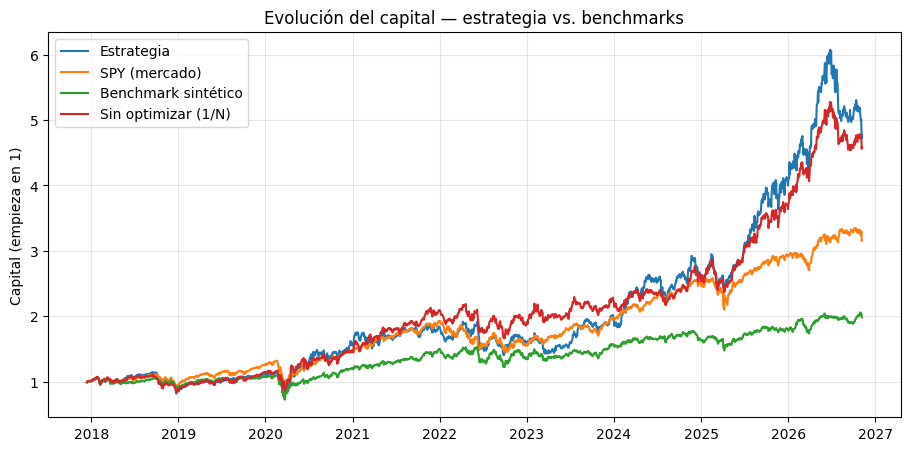

In [44]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

sen = SenalesUniverso(dl.precios, dl.sectores, cfg)
motor = Backtester(cfg, dl, sen, CarteraDosNiveles(cfg))
res = motor.correr()

print("Resumen de desempeño (retornos y Sharpe):")
tmp = res["resumen"].copy()
for c in ["retorno_total","vol_anual","max_drawdown"]:
    tmp[c] = (tmp[c]*100).round(2)
tmp["sharpe"] = tmp["sharpe"].round(3)
print(tmp.to_string())

vals = res["valor"]
nombres = {"estrategia":"Estrategia", "spy":"SPY (mercado)",
           "benchmark_sintetico":"Benchmark sintético", "equiponderada":"Sin optimizar (1/N)"}
plt.figure(figsize=(11, 5))
for c in vals.columns:
    plt.plot(vals.index, vals[c], label=nombres.get(c, c))
plt.title("Evolución del capital — estrategia vs. benchmarks")
plt.ylabel("Capital (empieza en 1)"); plt.legend(); plt.grid(alpha=0.3); plt.show()


# Fase 6 — Calibración por backtesting hacia adelante

Elegimos la configuración de la estrategia **con los datos**, no a dedo. Para cada
opción se compara el desempeño en un tramo de **calibración** (que el modelo "mira")
y en un tramo de **validación** fuera de muestra (que no vio). El criterio, fijado de
antemano, es el **Sharpe de validación**, con Max Drawdown y volatilidad de apoyo.

Se calibra en orden (escalonado): primero cuántos datos usa Markowitz, después cada
cuánto rebalancear, y por último cuántos sectores y acciones. La media móvil de 50
ruedas queda fija.

Los valores de partida (N=5, M=5) del Paso 3 son el punto de partida de esta calibración
escalonada: primero se calibran la ventana y la frecuencia, y al final N y M.

## Paso 4 — Eje 1: ¿cuántos datos usa Markowitz? (1, 2 o 3 años)

Corremos la misma estrategia con ventanas de 1, 2 y 3 años para la optimización,
comparadas en el período común (para que sea justo: con 3 años arranca más tarde).

In [45]:
calib = Calibrador(cfg, dl, sen)
t_ventanas = calib.comparar_ventanas(anios=(1, 2, 3), N=cfg.N_sectores, M=cfg.M_acciones)
print("Comparación de ventanas (Sharpe y riesgo):")
print(t_ventanas.round(3).to_string())

ventana_ganadora = int(t_ventanas["sharpe_valid"].idxmax().split("_")[0])
VENTANA_COV = ventana_ganadora * 252
print(f"\nVentana elegida por Sharpe fuera de muestra: {ventana_ganadora} año(s)  "
      f"-> {VENTANA_COV} ruedas")


Comparación de ventanas (Sharpe y riesgo):
         sharpe_full  ret_full  maxdd_full  vol_full  sharpe_calib  sharpe_valid  maxdd_valid  ret_valid
ventana                                                                                                 
1_anio         0.836     3.373      -0.284     0.264         0.434         1.301       -0.224      2.150
2_anio         0.798     3.070      -0.269     0.263         0.475         1.165       -0.269      1.817
3_anio         0.840     3.460      -0.304     0.267         0.733         0.965       -0.304      1.394

Ventana elegida por Sharpe fuera de muestra: 1 año(s)  -> 252 ruedas


## Paso 5 — Eje 2: frecuencia de rebalanceo (DECISIÓN: se mantiene la Fed)

Comparamos rebalancear en las reuniones de la Fed contra calendarios fijos (cada 1, 2,
3, 4 y 6 meses), como **chequeo de robustez**. **Decisión tomada:** se mantiene la Fed
como disparador por su justificación económica (ver Paso 10 / D9); la comparación se
muestra para ser transparentes, no como criterio para cambiar. Se incluye cuántas veces
rebalancea cada alternativa (sin costos de transacción, las más seguidas están
favorecidas).

In [46]:
t_frec = calib.comparar_frecuencias(meses_lista=(1, 2, 3, 4, 6),
                                     ventana_cov=VENTANA_COV,
                                     N=cfg.N_sectores, M=cfg.M_acciones)
print("Comparación de frecuencias (chequeo de robustez):")
print(t_frec.round(3).to_string())

# A título informativo: qué sugeriría la regla automática por Sharpe fuera de muestra.
sugerencia = Calibrador.elegir_frecuencia(t_frec, referencia="FOMC", margen=0.10)
print(f"\n(Informativo) la regla automática sugeriría: {sugerencia}")

# DECISIÓN TOMADA: se MANTIENE la Fed como disparador por su justificación económica.
# La comparación de arriba queda como robustez, no como criterio para cambiar.
frec_ganadora = "FOMC"
FECHAS = dl.fechas_rebalanceo
print(f"Frecuencia FIJADA por decisión: {frec_ganadora}  ({len(FECHAS)} rebalanceos)")


Comparación de frecuencias (chequeo de robustez):
            sharpe_full  ret_full  maxdd_full  vol_full  sharpe_calib  sharpe_valid  maxdd_valid  ret_valid  n_rebalanceos
frecuencia                                                                                                                
FOMC              0.731     3.770      -0.287     0.246         0.635         0.836       -0.265      1.672             75
cada_1m           0.647     2.830      -0.333     0.236         0.227         1.058       -0.260      2.295            108
cada_2m           0.684     3.199      -0.374     0.240         0.554         0.813       -0.226      1.587             54
cada_3m           0.763     4.056      -0.341     0.243         0.700         0.839       -0.206      1.582             36
cada_4m           0.936     6.482      -0.397     0.246         0.608         1.251       -0.275      3.289             27
cada_6m           0.729     4.128      -0.369     0.264         0.492         0.970      

## Paso 6 — Eje 3: ¿cuántos sectores (N) y acciones por sector (M)?

Con la ventana (1 año) y la frecuencia (**Fed**) ya fijadas, barremos N de 2 a 7 y M en
{3, 4, 5, 6, 7, 10} y armamos el **mapa de calor** del Sharpe fuera de muestra. Se
agregan M=4 y M=6 para confirmar bien el pico. Elegimos la combinación con mejor Sharpe,
prefiriendo zonas estables (vecinas parecidas) antes que un pico aislado.

Sharpe fuera de muestra por combinación N x M (optimizada):
      3      4      5      6      7      10
2  0.366  0.559  0.517  0.570  0.535  0.231
3  1.042  1.317  1.195  1.281  1.242  1.016
4  0.822  1.148  0.929  0.999  0.953  0.771
5  0.800  0.960  0.836  0.839  0.875  0.726
6  0.992  1.072  0.965  1.002  0.955  0.800
7  0.850  0.988  0.895  0.932  0.818  0.688

Mismo cuadro para la cartera SIN optimizar (1/N) — comparación obligatoria:
      3      4      5      6      7      10
2  0.501  0.522  0.478  0.523  0.388  0.306
3  1.032  1.061  1.003  1.022  0.901  0.771
4  0.915  0.966  0.792  0.821  0.726  0.586
5  0.931  0.972  0.827  0.855  0.761  0.643
6  1.076  1.110  0.986  0.974  0.875  0.783
7  1.060  1.034  0.942  0.912  0.843  0.743


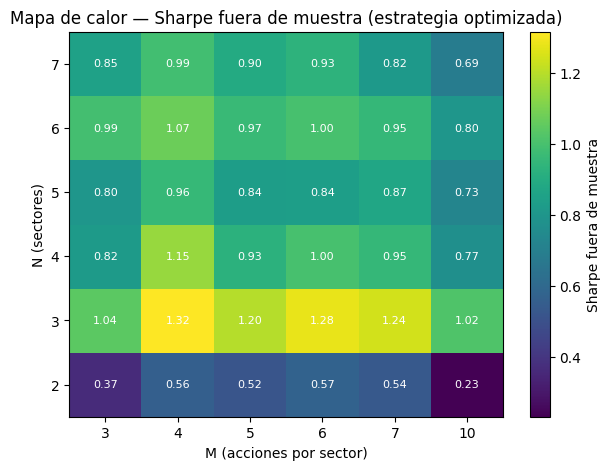


(Informativo) pico del mapa: N=3, M=4 (Sharpe=1.317).
Combinación FIJADA por decisión: N=3, M=6 (más diversificada que el pico)


In [47]:
g = calib.grilla_NM(lista_N=(2, 3, 4, 5, 6, 7), lista_M=(3, 4, 5, 6, 7, 10),
                     ventana_cov=VENTANA_COV, fechas_rebalanceo=FECHAS)
sh = g["sharpe_valid_opt"].astype(float)
print("Sharpe fuera de muestra por combinación N x M (optimizada):")
print(sh.round(3).to_string())
print("\nMismo cuadro para la cartera SIN optimizar (1/N) — comparación obligatoria:")
print(g["sharpe_valid_1N"].astype(float).round(3).to_string())

# Mapa de calor
plt.figure(figsize=(7, 5))
plt.imshow(sh.values, aspect="auto", origin="lower", cmap="viridis")
plt.colorbar(label="Sharpe fuera de muestra")
plt.xticks(range(len(sh.columns)), sh.columns); plt.yticks(range(len(sh.index)), sh.index)
plt.xlabel("M (acciones por sector)"); plt.ylabel("N (sectores)")
plt.title("Mapa de calor — Sharpe fuera de muestra (estrategia optimizada)")
for i in range(sh.shape[0]):
    for j in range(sh.shape[1]):
        plt.text(j, i, f"{sh.values[i,j]:.2f}", ha="center", va="center", color="white", fontsize=8)
plt.show()

# Pico del mapa (informativo) y decisión final.
mejor_pos = np.unravel_index(np.nanargmax(sh.values), sh.shape)
n_auto = int(sh.index[mejor_pos[0]]); m_auto = int(sh.columns[mejor_pos[1]])
print(f"\n(Informativo) pico del mapa: N={n_auto}, M={m_auto} (Sharpe={sh.values[mejor_pos]:.3f}).")

# DECISIÓN TOMADA: N=3, M=6. La fila N=3 domina el mapa de forma estable; dentro de esa
# fila, M=6 rinde casi igual que el pico (M=4) pero con más acciones -> más diversificación
# para la cartera del cliente. Por eso se fija acá en vez de tomar el pico automático.
N_FINAL, M_FINAL = 3, 6
print(f"Combinación FIJADA por decisión: N={N_FINAL}, M={M_FINAL} (más diversificada que el pico)")


## Paso 7 — Cartera final y su validación

Con los criterios elegidos en la calibración (ventana, frecuencia, N y M) armamos la
**cartera final** "hacia adelante". Mostramos su desempeño contra los benchmarks y contra
el punto de partida del Paso 3, su validación año a año (walk-forward), su comportamiento
por régimen de tasa (robustez) y su composición actual. Desde acá, todo lo que se calcula
es sobre esta cartera.

In [48]:
print(f"Configuración final -> ventana: {ventana_ganadora} año(s) | "
      f"frecuencia: {frec_ganadora} | N={N_FINAL} | M={M_FINAL}")

motor_final = Backtester(cfg, dl, sen, CarteraDosNiveles(cfg),
                         N=N_FINAL, M=M_FINAL, ventana_cov=VENTANA_COV, fechas_rebalanceo=FECHAS)
res_final = motor_final.correr()

print("\nDesempeño de la cartera recomendada vs. benchmarks:")
tmp = res_final["resumen"].copy()

# Retorno anual compuesto (CAGR): tasa constante por año que lleva del capital
# inicial al final en la misma cantidad de ruedas (252 ruedas = 1 año).
v_f = res_final["valor"]
n_ruedas = len(v_f) - 1
tmp["retorno_anual"] = (v_f.iloc[-1] / v_f.iloc[0]) ** (252 / n_ruedas) - 1
tmp = tmp[["retorno_total", "retorno_anual", "vol_anual", "max_drawdown", "sharpe"]]

for c in ["retorno_total", "retorno_anual", "vol_anual", "max_drawdown"]:
    tmp[c] = (tmp[c]*100).round(2)
tmp["sharpe"] = tmp["sharpe"].round(3)
print(tmp.to_string())

comp = pd.DataFrame({
    f"Punto de partida (N={cfg.N_sectores}, M={cfg.M_acciones})": res["resumen"].loc["estrategia"],
    f"Cartera final (N={N_FINAL}, M={M_FINAL})": res_final["resumen"].loc["estrategia"],
}).T
for c in ["retorno_total", "vol_anual", "max_drawdown"]:
    comp[c] = (comp[c] * 100).round(2)
comp["sharpe"] = comp["sharpe"].round(3)
print("\nAntes vs. después de calibrar (estrategia):")
print(comp.to_string())

# Walk-forward año a año (estabilidad) y regímenes de tasa (robustez)
wf = calib.walk_forward(N_FINAL, M_FINAL, VENTANA_COV, FECHAS, anios_calib=3, anios_test=1)
print("\nValidación año a año (walk-forward) de la cartera recomendada:")
print(wf.round(3).to_string(index=False))

print("\nDesempeño por régimen de tasa (robustez):")
print(calib.por_regimen(res_final["retornos"]["estrategia"]).round(3).to_string())

# Composición recomendada hoy
pesos_final = next((w for t, w in reversed(list(motor_final.pesos_por_rebalanceo.items())) if len(w) > 0), None)
print("\nComposición de la cartera recomendada (top 15, %):")
print((pesos_final.sort_values(ascending=False).head(15)*100).round(2).to_string())


Configuración final -> ventana: 1 año(s) | frecuencia: FOMC | N=3 | M=6

Desempeño de la cartera recomendada vs. benchmarks:
                     retorno_total  retorno_anual  vol_anual  max_drawdown  sharpe
estrategia                  877.19          29.31      23.44        -26.87   1.097
spy                         217.67          13.92      18.94        -33.72   0.640
benchmark_sintetico         176.12          12.13      18.00        -33.01   0.576
equiponderada               573.25          23.99      22.53        -28.35   0.944

Antes vs. después de calibrar (estrategia):
                             retorno_total  vol_anual  max_drawdown  sharpe
Punto de partida (N=5, M=5)         380.82      24.60        -28.74   0.731
Cartera final (N=3, M=6)            877.19      23.44        -26.87   1.097

Validación año a año (walk-forward) de la cartera recomendada:
     desde      hasta  sharpe  max_drawdown  retorno_tramo
2020-12-14 2021-12-14   2.396        -0.099          0.632
2021-

## Paso 8 — Riesgo de la cartera final: VaR, CAPM y stress testing

VaR por los tres métodos (paramétrico, histórico, Monte Carlo), Alpha/Beta de las tres
carteras contra el SPY (la consigna pide el CAPM "de los portafolios") y stress testing
(crisis históricas y shocks hipotéticos), todo sobre la cartera final.

In [49]:
rk_f = RiskMetrics(cfg)
print("VaR de la cartera final (pérdida diaria, %):")
print((rk_f.tabla_var(res_final["retornos"]["estrategia"]) * 100).round(3).to_string())

capm_f = capm_todas(res_final, dl.rf_diaria).copy()
capm_f["alpha_anual_%"] = (capm_f["alpha_anual"] * 100).round(2)
print("\nCAPM vs SPY (cartera final y benchmarks):")
print(capm_f[["beta", "alpha_anual_%", "r2"]].round(3).to_string())

st_f = StressTester(cfg)
print("\nStress histórico de la cartera final (%):")
print((st_f.escenarios_historicos(pesos_final, dl.retornos) * 100).round(2).to_string())

beta_f = capm_f.loc["estrategia", "beta"]
print(f"\nShocks hipotéticos de mercado (vía Beta={beta_f:.2f}):")
for s in (-0.10, -0.20):
    print(f"  mercado {int(s*100)}%  ->  cartera final {st_f.shock_mercado(beta_f, s)*100:.2f}%")

# Shock de tasa: usa los pesos de sector del último rebalanceo y la sensibilidad sectorial.
traza_ult = [tr for tr in motor_final.traza_rebalanceos if not tr.get("caja")][-1]
pesos_sec = traza_ult["pesos_sector"]
betas_tasa = RateSensitivity(cfg, dl).betas_sectoriales()
for d in (0.005, 0.01):   # +50 y +100 puntos básicos
    print(f"  tasa +{int(d*10000)}pb  ->  cartera final {st_f.shock_tasa(pesos_sec, betas_tasa, d)*100:.2f}%")


VaR de la cartera final (pérdida diaria, %):
     parametrico  historico  montecarlo
95%        2.316      2.222       2.360
99%        3.323      4.292       3.393

CAPM vs SPY (cartera final y benchmarks):
                      beta  alpha_anual_%     r2
estrategia           0.809          15.92  0.428
equiponderada        0.806          11.51  0.459
benchmark_sintetico  0.797           0.72  0.703

Stress histórico de la cartera final (%):
                    retorno_acumulado  max_drawdown  peor_dia
COVID 2020                     -48.21        -48.64    -14.65
Suba de tasas 2022               2.39        -18.85     -5.53

Shocks hipotéticos de mercado (vía Beta=0.81):
  mercado -10%  ->  cartera final -8.09%
  mercado -20%  ->  cartera final -16.18%
  tasa +50pb  ->  cartera final 2.60%
  tasa +100pb  ->  cartera final 5.20%


## Paso 9 — Gráficos de la cartera final

Capital acumulado, caídas desde el máximo y **volatilidad móvil** (gráficos de la
consigna), más la **frontera eficiente**: las mejores combinaciones de riesgo y retorno
posibles con las acciones del último rebalanceo, marcando dónde cae la cartera final.

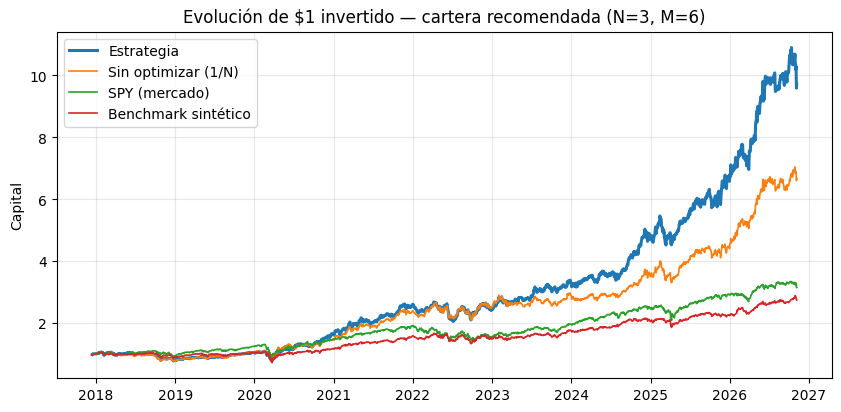

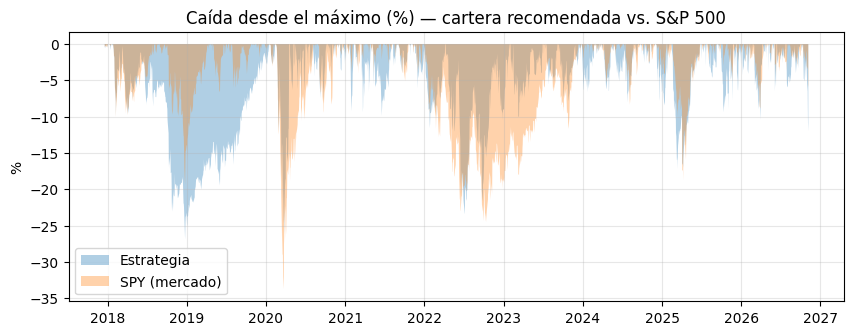

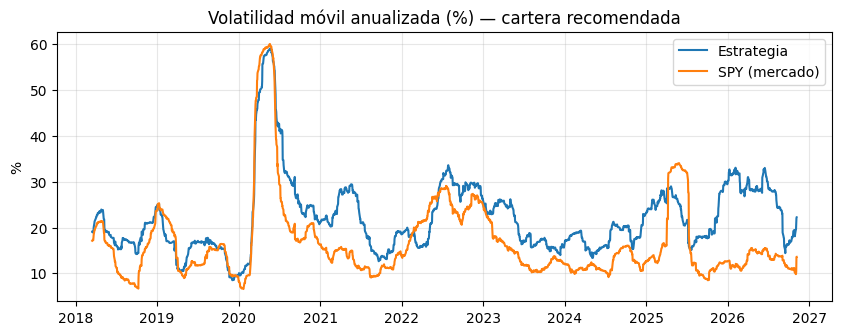

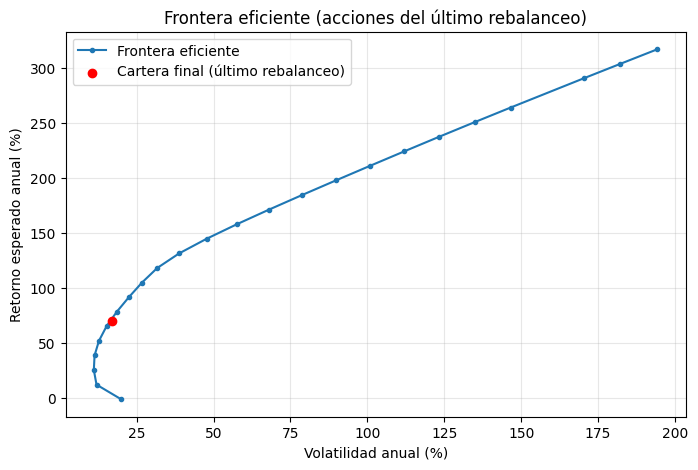

In [50]:
# Capital, caídas desde el máximo y volatilidad móvil, sobre la configuración final.

v, r = res_final["valor"], res_final["retornos"]

# 1) Evolución del capital: estrategia vs. benchmarks
plt.figure(figsize=(10, 4.5))
for c in ["estrategia", "equiponderada", "spy", "benchmark_sintetico"]:
    plt.plot(v.index, v[c], label=nombres[c], lw=2.2 if c == "estrategia" else 1.2)
plt.title("Evolución de $1 invertido — cartera recomendada (N=3, M=6)")
plt.ylabel("Capital"); plt.legend(); plt.grid(alpha=0.3); plt.show()

# 2) Caída desde el máximo (drawdown): estrategia vs. S&P 500
plt.figure(figsize=(10, 3.5))
for c in ["estrategia", "spy"]:
    dd = (v[c] / v[c].cummax() - 1) * 100      # caída relativa respecto del pico, en %
    plt.fill_between(dd.index, dd, 0, alpha=0.35, label=nombres[c])
plt.title("Caída desde el máximo (%) — cartera recomendada vs. S&P 500")
plt.ylabel("%"); plt.legend(loc="lower left"); plt.grid(alpha=0.3); plt.show()

# 3) Volatilidad móvil anualizada (63 ruedas)
plt.figure(figsize=(10, 3.5))
for c in ["estrategia", "spy"]:
    plt.plot(volatilidad_rolling(r[c], cfg.ventana_vol_rolling) * 100, label=nombres[c])
plt.title("Volatilidad móvil anualizada (%) — cartera recomendada")
plt.ylabel("%"); plt.legend(); plt.grid(alpha=0.3); plt.show()

# 4) Frontera eficiente con las acciones del último rebalanceo de la cartera final
t_ult = [t for t, w in motor_final.pesos_por_rebalanceo.items() if len(w) > 0][-1]
pos = dl.calendario.get_loc(t_ult)
ventana = motor_final.retornos.iloc[pos - motor_final.ventana_cov + 1: pos + 1]
sel = [tk for tk in pesos_final.index if tk in ventana.columns]
rv = ventana[sel].dropna(how="any")
w_fin = pesos_final[rv.columns].values; w_fin = w_fin / w_fin.sum()

opt = Optimizador(cfg)
rets_f, vols_f = opt.frontera_eficiente(rv, n_puntos=25)
m_fin = opt.metricas(w_fin, rv)
plt.figure(figsize=(8, 5))
plt.plot(np.array(vols_f) * 100, np.array(rets_f) * 100, "-o", ms=3, label="Frontera eficiente")
plt.scatter([m_fin["vol"] * 100], [m_fin["retorno"] * 100], c="red", zorder=5,
            label="Cartera final (último rebalanceo)")
plt.title("Frontera eficiente (acciones del último rebalanceo)")
plt.xlabel("Volatilidad anual (%)"); plt.ylabel("Retorno esperado anual (%)")
plt.legend(); plt.grid(alpha=0.3); plt.show()


## Paso 10 — Reacción sectorial el día de la Fed (justificación económica, D9)

Medimos la reacción de cada sector (ETF) el día de la reunión, como el retorno de
cierre a cierre de ese día (retorno puro, sin restar el SPY). Es la justificación de
por qué la Fed es un buen disparador: los sectores no reaccionan igual. **No entra
como señal** de la estrategia (ese movimiento ya está dentro de la media móvil de 50).

Limitaciones: un solo día por reunión y muestra ruidosa; las reuniones extraordinarias
de 2020 se miran aparte; con datos diarios no se separa 'sorpresa' de 'esperado'.

Reacción media de cada sector el día de la reunión (sin extraordinarias 2020):
                        media_%  desvio_%  t_stat  n_reuniones
Information Technology    0.267     1.654   1.443         80.0
Communication Services    0.043     1.606   0.219         67.0
Consumer Discretionary    0.011     1.503   0.065         80.0
Industrials              -0.036     1.167  -0.276         80.0
Energy                   -0.075     1.847  -0.362         80.0
Health Care              -0.101     0.938  -0.960         80.0
Financials               -0.126     1.337  -0.840         80.0
Materials                -0.163     1.291  -1.132         80.0
Utilities                -0.169     1.018  -1.487         80.0
Real Estate              -0.229     1.256  -1.633         80.0
Consumer Staples         -0.284     0.882  -2.878         80.0


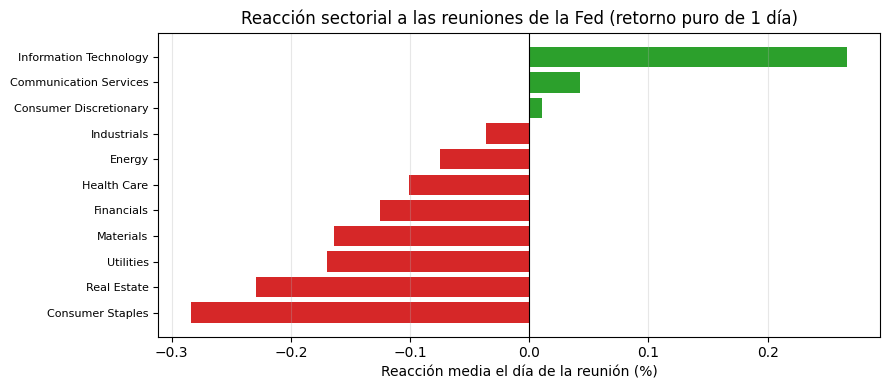


Reacción media por tipo de decisión de la Fed (%):
                        subió   bajó  mantuvo
Information Technology  0.267 -1.452    0.531
Financials             -0.290 -1.940    0.178
Energy                 -0.598 -1.730    0.333
Health Care             0.073 -1.264   -0.136
Industrials            -0.008 -1.446    0.089
Consumer Discretionary  0.102 -1.327    0.150
Consumer Staples       -0.163 -1.112   -0.265
Utilities              -0.273 -1.322   -0.047
Materials              -0.151 -1.545   -0.045
Real Estate            -0.520 -1.777    0.037
Communication Services  0.228 -1.094    0.091

Persistencia: retorno acumulado promedio a 1/3/5 días (%):
                         1d_%   3d_%   5d_%
Information Technology  0.267  0.012  0.380
Financials             -0.126 -0.475 -0.512
Energy                 -0.075 -0.632 -0.688
Health Care            -0.101 -0.221 -0.248
Industrials            -0.036 -0.242 -0.077
Consumer Discretionary  0.011 -0.288  0.008
Consumer Staples       -0.28

In [51]:
rf_ev = ReaccionFOMC(cfg, dl)
resumen_sec = rf_ev.resumen_por_sector(excluir_no_programadas=True)
print("Reacción media de cada sector el día de la reunión (sin extraordinarias 2020):")
print(resumen_sec.round(3).to_string())

# Gráfico de barras ordenado
plt.figure(figsize=(9, 4))
orden = resumen_sec.sort_values("media_%")
colores = ["tab:red" if v < 0 else "tab:green" for v in orden["media_%"]]
plt.barh(range(len(orden)), orden["media_%"], color=colores)
plt.yticks(range(len(orden)), orden.index, fontsize=8)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Reacción media el día de la reunión (%)")
plt.title("Reacción sectorial a las reuniones de la Fed (retorno puro de 1 día)")
plt.grid(alpha=0.3, axis="x"); plt.tight_layout(); plt.show()

print("\nReacción media por tipo de decisión de la Fed (%):")
print(rf_ev.por_tipo_decision().round(3).to_string())
print("\nPersistencia: retorno acumulado promedio a 1/3/5 días (%):")
print(rf_ev.persistencia(horizontes=(1,3,5)).round(3).to_string())


## Paso 11 — Chequeos finales (verde = anda)

In [52]:
vals_f = res_final["valor"]
ok = total = 0
def chequeo(desc, cond):
    global ok, total; total += 1; ok += int(bool(cond))
    print(("[OK]   " if cond else "[FALLA]") + " " + desc)

chequeo("La curva de valor reproduce los retornos",
        np.isclose(vals_f['estrategia'].iloc[-1], (1+res_final['retornos']['estrategia'].fillna(0)).prod()))
chequeo("Maximum Drawdown <= 0", maximum_drawdown(vals_f['estrategia']) <= 0)
chequeo("Pesos de la cartera final suman 1", np.isclose(pesos_final.sum(), 1.0))
chequeo("Posiciones activas <= N x M", (pesos_final > 0).sum() <= N_FINAL * M_FINAL)
chequeo("Sharpe presente en el resumen", "sharpe" in res_final["resumen"].columns)
chequeo("CAPM de las 3 carteras calculado", capm_f.shape[0] == 3)
chequeo("Beta de SPY contra sí mismo = 1",
        np.isclose(CAPM.estimar(res_final['retornos']['spy'], res_final['retornos']['spy'], dl.rf_diaria)['beta'], 1.0, atol=1e-6))
chequeo("Los 3 VaR al 95% son del mismo orden",
        (lambda t: t.max()/t.min() < 3)(rk_f.tabla_var(res_final['retornos']['estrategia']).loc['95%']))
print(f"\nResultado: {ok}/{total} chequeos en verde.")


[OK]    La curva de valor reproduce los retornos
[OK]    Maximum Drawdown <= 0
[OK]    Pesos de la cartera final suman 1
[OK]    Posiciones activas <= N x M
[OK]    Sharpe presente en el resumen
[OK]    CAPM de las 3 carteras calculado
[OK]    Beta de SPY contra sí mismo = 1
[OK]    Los 3 VaR al 95% son del mismo orden

Resultado: 8/8 chequeos en verde.
